# Part 14, notebook 3 of 6: the results, and why they are not "the checklist wins"

**The picture.** Five exams, each with an exact answer key. Some are held in a huge library (the table), some in a small one (200 reports that fit on the desk), some need a *meaning* search, some need an *image* search. We compare six ways of working, and count only exact answers.

This notebook **reads the saved runs** (`out/ctx_eval_runs.json`, `out/ctx_subagent_runs.json`); it does not call the model. The runs took hours; every number in the post comes from these files.

In [1]:
import sys, json, os
from pathlib import Path
os.environ.setdefault("AGENTIC_ZERO_MODEL", "qwen3.8-27b")   # the model name the local vLLM server serves (as in the post)
os.environ.setdefault("RUST_LOG", "error"); os.environ.setdefault("LANCE_LOG", "error")   # silence LanceDB deprecation chatter
import warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve()))                # this notebook lives in literate/, the code in notebooks/agentic-zero-to-advanced/
OUT = Path("..").resolve() / "out"
import ctx_summary as s
from ctx_eval import build_tasks
runs = json.loads((OUT / "ctx_eval_runs.json").read_text())
print(len(runs), "saved runs;", len({r["question"] for r in runs}), "questions")

71 saved runs; 17 questions


## The five tasks, with the answer key

Gold answers are computed from the same files the agent sees, so a run is simply right or wrong.

In [2]:
tasks = build_tasks()
seen = set()
for t in tasks:
    if t["task"] in seen: continue
    seen.add(t["task"])
    gold = t.get("gold", f"{len(t.get('gold_ids', []))} acceptable report ids")
    print(f"{t['task']}  {s.TASK_NAMES[t['task']]}\n    q:    {t['q'][:150].replace(chr(10), ' ')}...\n    gold: {gold}\n")
from collections import Counter
print("questions per task:", dict(Counter(t["task"] for t in tasks)))

T1  needle in a 4,000-row CSV
    q:    In exports/inspection_log.csv, what are n_voids and void_area for the row with id test_00331? Answer: ANSWER: {"n_voids": int, "void_area": int}...
    gold: {'n_voids': 1, 'void_area': 156}

T2  count across 200 reports
    q:    How many reports in reports/ have verdict escalate AND at least one kept candidate with severity critical? Answer: ANSWER: {"count": int}...
    gold: {'count': 10}

T3  stale vs current policy
    q:    What is the smallest void area, in pixels, that the pipeline reports? Name the policy file you used. Answer: ANSWER: {"min_area_px": int, "source": "<...
    gold: {'min_area_px': 20, 'source': 'policy-2026-10-17.md'}

T4  find 4 reports by meaning
    q:    Find 4 reports where a human should double-check a defect that the model was unsure about. Answer: ANSWER: {"ids": ["test_00000", ...4 report ids]}...
    gold: 36 acceptable report ids

T5  20 visual neighbours (DINOv3 + LanceDB)
    q:    cases/ holds one record p

[2026-10-26T09:30:49Z WARN  lance::dataset::scanner] Deprecation warning, this behavior will change in the future. This search specified output columns but did not include `_distance`.  Currently the `_distance` column will be included.  In the future it will not.  Call `disable_scoring_autoprojection` to adopt the future behavior and avoid this warning
[2026-10-26T09:30:49Z WARN  lance::dataset::scanner] Deprecation warning, this behavior will change in the future. This search specified output columns but did not include `_distance`.  Currently the `_distance` column will be included.  In the future it will not.  Call `disable_scoring_autoprojection` to adopt the future behavior and avoid this warning
[2026-10-26T09:30:49Z WARN  lance::dataset::scanner] Deprecation warning, this behavior will change in the future. This search specified output columns but did not include `_distance`.  Currently the `_distance` column will be included.  In the future it will not.  Call `disable_scoring_

## The table

*Overflow*: the request exceeded the 65,536-token window and the server refused it. *Cap*: the agent used all 14 steps without answering. *Mean total tokens*: prompt tokens summed over every step (plus sub-agent tokens), i.e. what the loop actually re-reads.

In [3]:
print(f"{'task':4} {'strategy':22} {'ok':>5} {'ovfl':>4} {'cap':>4} {'peak tok':>9} {'mean total tok':>15} {'s':>6}")
last = None
for r in s.table():
    if last and r["task"] != last: print()
    last = r["task"]
    print(f"{r['task']:4} {r['strategy']:22} {r['correct']}/{r['n']:<3} {r['overflow']:4d} {r['max_steps']:4d} {r['peak_tokens']:9d} {r['mean_total_tokens']:15d} {r['mean_seconds']:6.1f}")

task strategy                  ok ovfl  cap  peak tok  mean total tok      s
T1   stuff                  0/6      6    0         0               0    0.4
T1   payload                0/6      6    0       543             543    2.3
T1   harness                6/6      0    0      1270            2834    9.4
T1   harness+delegate       3/6      0    3      3343           16535   45.3

T2   stuff                  3/3      0    0     28300           28300  145.7
T2   payload                0/3      2    1     14879           34771   44.4
T2   harness                0/3      0    3     29514          111476  107.5
T2   harness+delegate       0/3      0    3      8118           65201   84.4

T3   stuff                  2/2      0    0       453             452   10.2
T3   payload                1/2      1    0      1146            2294   11.6
T3   harness                1/2      0    1     14841           53299   51.8
T3   harness+delegate       1/2      0    1     14575           51633   56

## The same data as bars

One bar per strategy: how many tokens the loop re-read in total. The red line is the context window. A bar that would cross it is a run that overflowed.

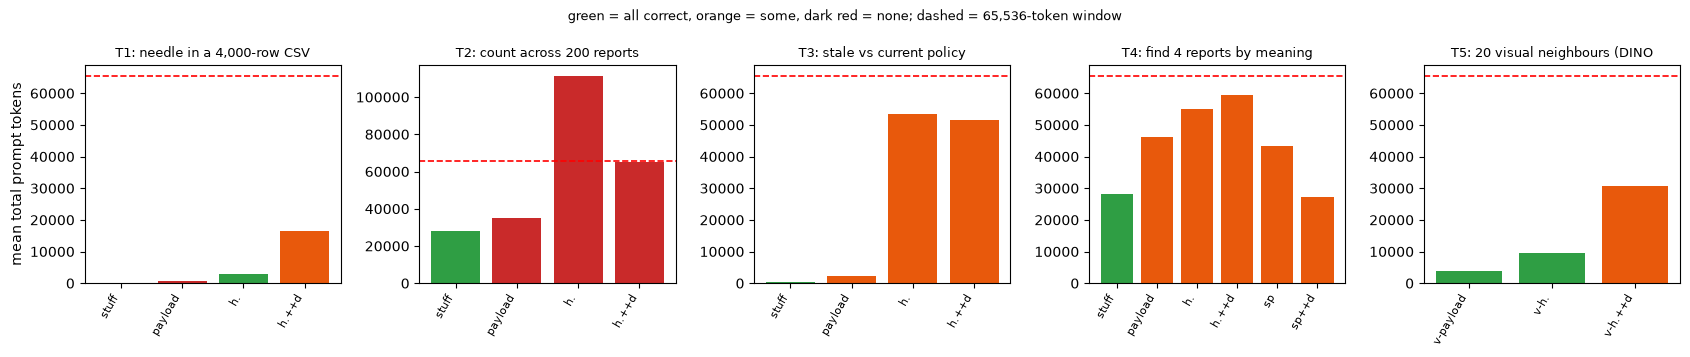

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
tab = s.table()
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharey=False)
for ax, task in zip(axes, ["T1", "T2", "T3", "T4", "T5"]):
    rows = [r for r in tab if r["task"] == task]
    names = [r["strategy"].replace("harness", "h.").replace("search-paths", "sp").replace("delegate", "+d") for r in rows]
    vals = [r["mean_total_tokens"] for r in rows]
    cols = ["#2f9e44" if r["correct"] == r["n"] else "#e8590c" if r["correct"] else "#c92a2a" for r in rows]
    ax.bar(range(len(rows)), vals, color=cols)
    ax.axhline(65536, color="red", lw=1.2, ls="--")
    ax.set_xticks(range(len(rows))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{task}: {s.TASK_NAMES[task][:26]}", fontsize=9)
axes[0].set_ylabel("mean total prompt tokens")
fig.suptitle("green = all correct, orange = some, dark red = none; dashed = 65,536-token window", fontsize=9)
plt.tight_layout(); plt.show()

## Reading it

- **T1, the table.** `stuff` and `payload` fail every time (the table is four times the window). The harness gets 6 of 6 with about 2,800 tokens in total, roughly one fortieth of the CSV. This is the article's claim, holding.
- **T2, counting.** Pasting all 200 reports in gets 3 of 3. Every tool arm gets 0 of 3: they run out of steps intersecting two lists by hand. When everything fits, stuffing is a legitimate strategy, and a ten-line script would beat both. That last part is a prediction, not a measurement.
- **T4, by meaning.** The arms with grep did no better than the one without it: the question was phrased as an idea, so the right words were not known.
- **T5, images.** The plain payload arm wins (3 of 3, 3,949 tokens). 20 small records are only about 3,000 tokens, so the machinery is overhead.

**The sub-agent made T1 worse** (6 of 6 down to 3 of 6). On the three failures the model never even called `analyze`. I did not find out why.

### Evidence for that claim: what the three failing delegate runs actually did

In [5]:
t1d = [r for r in runs if r["task"] == "T1" and r["strategy"] == "harness+delegate"]
for r in t1d:
    print(f"correct={r['correct']!s:5s} status={r['status']:9s} steps={r['steps']:2d} tools_used={r['tools_used']}")

correct=False status=max_steps steps=14 tools_used={'grep': 1, 'read_file': 13}
correct=False status=max_steps steps=14 tools_used={'grep': 1, 'read_file': 13}
correct=True  status=ok        steps= 4 tools_used={'grep': 1, 'read_file': 2}
correct=False status=max_steps steps=14 tools_used={'grep': 1, 'read_file': 13}
correct=True  status=ok        steps= 4 tools_used={'grep': 1, 'read_file': 2}
correct=True  status=ok        steps= 3 tools_used={'grep': 1, 'read_file': 1}


## The bug that flipped a result

My first run capped answers at 1,200 tokens. A model that counts by writing a list needs far more, so the `stuff` arm was cut off mid-list and scored 0 of 3 on counting. The tell: the saved answers all ended mid-sentence at exactly 1,200 completion tokens. Check the kept old file.

In [6]:
old = json.loads((OUT / "old_ctx_eval_runs_maxtok1200.json").read_text())
cut = [r for r in old if r["strategy"] == "stuff" and r["task"] in ("T2", "T4")]
print("old stuff runs on T2/T4:", [(r["task"], r["correct"], r["completion_tokens"]) for r in cut])
new = [r for r in runs if r["strategy"] == "stuff" and r["task"] in ("T2", "T4")]
print("new stuff runs on T2/T4:", [(r["task"], r["correct"], r["completion_tokens"]) for r in new])

old stuff runs on T2/T4: [('T2', False, 1200), ('T2', False, 1200), ('T2', False, 1200), ('T4', False, 1200), ('T4', False, 1200), ('T4', True, 418)]
new stuff runs on T2/T4: [('T2', True, 2031), ('T2', True, 2347), ('T2', True, 1981), ('T4', True, 3317), ('T4', True, 3209), ('T4', True, 418)]


## Does the visual retrieval itself work?

Scoring an agent on neighbours I defined as correct would be circular, so retrieval quality was measured separately: of the 4 nearest DINOv3 neighbours of each of 600 test images, how many are the same kind of part?

In [7]:
print((OUT / "ctx_visual_quality_output.txt").read_text())

share of the 4 nearest DINOv3 neighbours with the same part class: 0.728 (random neighbours: 0.101; 600 queries)



**72.8 % against 10.1 % for random neighbours**, about seven times better than chance, on images DINOv3 was never trained on. Retrieval works; what varies is whether the *agent* needs machinery to use it.

**Not covered:** one local model, one run per question (the samples are small: a difference of one run is noise), and the harness row of later comparisons uses the best set-up per task, which flatters it.